##Fraud Language Analysis

The notebook investigates the words and phrases associated with fraudulent and authentic job postings in the dataset.

It looks at the classification models built in the previous notebooks by analyzing the regression coefficients to find impactful words or phrases when attempting to identify fraud.

It also looks at whether the impactful language differs between the posting categories such as description, benefits, or company profile.

The notebook should provide some insight into the text characteristics of fraudulent job postings.

The analysis is performed on the training data to determine the terms that were most impactful for the model to make classification decisions.

In [ ]:
#some of the main requirements
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
#mounts google drive, grabs the cleaned dataset and split from the previous notebooks
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv(
    '/content/drive/MyDrive/fake_job_postings_cleaned.csv'
)

split_assignments = pd.read_csv(
    '/content/drive/MyDrive/job_posting_split.csv'
)
#merges the cleaned postings and split using the job_id
analysis_df = df.merge(
    split_assignments,
    on='job_id',
    how='inner',
    validate='one_to_one'
)
#displays the shape and value counts. should be (17878, 24)
print("Dataset shape:", analysis_df.shape)
print(analysis_df['split'].value_counts())

Mounted at /content/drive
Dataset shape: (17878, 24)
split
train    14274
test      3604
Name: count, dtype: int64


In [ ]:
#pulls the training entries and copies them to train_df
train_df = analysis_df[
    analysis_df['split'] == 'train'
].copy()

print(
    train_df['fraudulent'].value_counts()
)

fraudulent
0    13584
1      690
Name: count, dtype: int64


In [ ]:
#grabs the trained models from the previous notebooks
import joblib

tfidf_model = joblib.load(
    '/content/drive/MyDrive/tfidf_tuned_model.joblib'
)

expanded_model = joblib.load(
    '/content/drive/MyDrive/expanded_fraud_model.joblib'
)

#displays the details of both the description only model and the expanded model
print("Description-only model:")
print(tfidf_model)

print("\nExpanded model:")
print(expanded_model)

Description-only model:
Pipeline(steps=[('vectorizer', TfidfVectorizer(min_df=3, ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(C=10, class_weight='balanced',
                                    max_iter=1000, random_state=42))])

Expanded model:
Pipeline(steps=[('features',
                 ColumnTransformer(transformers=[('description',
                                                  TfidfVectorizer(min_df=3,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'description_repaired'),
                                                 ('company_profile',
                                                  TfidfVectorizer(min_df=3,
                                                                  ngram_range=(1,
                                                                         

##Description only model analysis

In [ ]:
#pulls the words and phrases used by the description only model as well as the coefficients to determine their level of influence
vectorizer = tfidf_model.named_steps['vectorizer']
classifier = tfidf_model.named_steps['classifier']

feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]
#displays the number of features in the TF-IDF vocab and the regression coefficients
print("Number of features:", len(feature_names))
print("Number of coefficients:", len(coefficients))

Number of features: 138298
Number of coefficients: 138298


In [ ]:
#pulls the text values and the corresponding coefficients to find the most impactful terms. Positive pushes the prediction toward fraudulent
term_coefficients = pd.DataFrame({
    'term': feature_names,
    'coefficient': coefficients
})

term_coefficients = term_coefficients.sort_values(
    'coefficient',
    ascending=False
)

display(term_coefficients.head(20))

,term,coefficient
69686,link urltoken,6.472653
17862,below link,5.650032
129241,using below,5.650032
32940,data entry,5.486939
11885,apply using,5.420230
76313,money,5.414189
14451,assistant,5.392178
105153,sales executive,4.711020
42633,entry,4.491136
4421,aker,4.482036


In [ ]:
#displays the 20 most negative terms. Negative pushes the prediction away from fraudulent. These terms are associated with authentic postings
display(
    term_coefficients.tail(20).sort_values(
        'coefficient'
    )
)

,term,coefficient
86414,our,-5.909091
131924,web,-4.150383
116728,team,-3.830716
129036,user,-3.752897
73386,marketing,-3.526033
54114,growing,-3.467805
24733,client,-3.454784
16424,based,-3.397079
65510,it,-3.348798
41205,end,-3.299748


In [ ]:
#lists some of the words and phrases for further analysis
terms_to_examine = [
    'money',
    'earn',
    'from home',
    'data entry',
    'administrative assistant',
    'link urltoken',
    'apply using',
    'team',
    'our',
    'developer',
    'client',
    'aker solutions'
]

In [ ]:
#uses the sklearn binarize to look at term prevalence or the percentage of postings in each class contains a term
from sklearn.preprocessing import binarize

#converts each repaired description into a matrix where each row is a description and each column is a separate word or phrase. Values are the tf-idf weight for that term in a particular description
X_terms = vectorizer.transform(
    train_df['description_repaired'].fillna('')
)

#convert TF-IDF values into binary exists or not for a description
X_binary = binarize(X_terms, threshold=0)

#grabs the class of each row as either fraudulent or not
fraud_mask = train_df['fraudulent'].to_numpy() == 1
legit_mask = ~fraud_mask

#initilize empty list
term_prevalence = []

#loops through the terms looking for the ones we specified earlier for additional analysis
for term in terms_to_examine:

    if term not in vectorizer.vocabulary_:
        continue

    term_index = vectorizer.vocabulary_[term]

    #calculates the percentage of fraudulent or authentic postings that contain that particular term
    fraud_rate = (
        X_binary[fraud_mask, term_index].mean()
    )

    legit_rate = (
        X_binary[legit_mask, term_index].mean()
    )

    term_prevalence.append({
        'Term': term,
        'Fraudulent (%)': fraud_rate * 100,
        'Legitimate (%)': legit_rate * 100
    })

prevalence_df = pd.DataFrame(term_prevalence)

display(prevalence_df.round(2))

,Term,Fraudulent (%),Legitimate (%)
0,money,7.83,2.29
1,earn,9.28,0.93
2,from home,8.99,0.85
3,data entry,10.00,1.16
4,administrative assistant,4.35,0.28
5,link urltoken,6.09,0.02
6,apply using,4.06,0.01
7,team,34.35,53.90
8,our,40.00,60.12
9,developer,2.17,8.58


In [ ]:
#displays the fraudulent, legitimate, and prevalence ratios for the selected terms. displays in descending order based on prevalence ratio. Some terms may be irregularly high due to descriptions that are duplicated across separate postings
prevalence_df['Prevalence Ratio'] = (
    prevalence_df['Fraudulent (%)'] /
    prevalence_df['Legitimate (%)'].replace(0, np.nan)
)

display(
    prevalence_df.sort_values(
        'Prevalence Ratio',
        ascending=False
    ).round(2)
)

,Term,Fraudulent (%),Legitimate (%),Prevalence Ratio
6,apply using,4.06,0.01,275.62
5,link urltoken,6.09,0.02,275.62
4,administrative assistant,4.35,0.28,15.54
2,from home,8.99,0.85,10.61
1,earn,9.28,0.93,10.00
3,data entry,10.00,1.16,8.60
0,money,7.83,2.29,3.42
8,our,40.00,60.12,0.67
7,team,34.35,53.90,0.64
10,client,9.57,18.54,0.52


In [ ]:
#removes descriptions that are repeated across different postings
unique_train_df = (
    train_df
    .drop_duplicates(
        subset=['description_repaired', 'fraudulent']
    )
    .copy()
)

#displays the original training description count and the unique descriptions to determine how many are duplicated
print("Original training postings:", len(train_df))
print("Unique descriptions by class:", len(unique_train_df))

print("\nClass distribution:")
print(unique_train_df['fraudulent'].value_counts())

Original training postings: 14274
Unique descriptions by class: 11612

Class distribution:
fraudulent
0    11122
1      490
Name: count, dtype: int64


In [ ]:
#repeats the term analysis using only unique descriptions
X_unique = vectorizer.transform(
    unique_train_df['description_repaired'].fillna('')
)

X_unique_binary = binarize(
    X_unique,
    threshold=0
)

unique_fraud_mask = (
    unique_train_df['fraudulent'].to_numpy() == 1
)

unique_legit_mask = ~unique_fraud_mask

unique_prevalence = []

for term in terms_to_examine:

    if term not in vectorizer.vocabulary_:
        continue

    term_index = vectorizer.vocabulary_[term]

    fraud_rate = X_unique_binary[
        unique_fraud_mask, term_index
    ].mean()

    legit_rate = X_unique_binary[
        unique_legit_mask, term_index
    ].mean()

    unique_prevalence.append({
        'Term': term,
        'Fraudulent (%)': fraud_rate * 100,
        'Legitimate (%)': legit_rate * 100
    })

unique_prevalence_df = pd.DataFrame(
    unique_prevalence
)

display(unique_prevalence_df.round(2))

,Term,Fraudulent (%),Legitimate (%)
0,money,4.69,2.29
1,earn,8.37,0.87
2,from home,6.33,0.86
3,data entry,6.73,1.23
4,administrative assistant,4.08,0.33
5,link urltoken,8.57,0.03
6,apply using,5.71,0.02
7,team,34.08,57.55
8,our,40.41,62.20
9,developer,2.45,9.58


In [ ]:
#combines the results of the original descriptions and the unique descriptions to determine the difference
prevalence_comparison = prevalence_df[
    ['Term', 'Fraudulent (%)', 'Legitimate (%)']
].merge(
    unique_prevalence_df,
    on='Term',
    suffixes=('_Postings', '_Unique')
)

display(prevalence_comparison.round(2))

,Term,Fraudulent (%)_Postings,Legitimate (%)_Postings,Fraudulent (%)_Unique,Legitimate (%)_Unique
0,money,7.83,2.29,4.69,2.29
1,earn,9.28,0.93,8.37,0.87
2,from home,8.99,0.85,6.33,0.86
3,data entry,10.00,1.16,6.73,1.23
4,administrative assistant,4.35,0.28,4.08,0.33
5,link urltoken,6.09,0.02,8.57,0.03
6,apply using,4.06,0.01,5.71,0.02
7,team,34.35,53.90,34.08,57.55
8,our,40.00,60.12,40.41,62.20
9,developer,2.17,8.58,2.45,9.58


In [ ]:
#aker solutions appears an unusual number of times for being a company name. Looks at the postings that contain aker solutions
aker_postings = train_df[
    train_df['description_repaired']
    .str.contains('aker solutions', case=False, na=False, regex=False)
].copy()

aker_unique = aker_postings.drop_duplicates(
    subset=['description_repaired']
)

print("Total matching postings:", len(aker_postings))
print("Unique descriptions:", len(aker_unique))

print("\nFraud labels:")
print(aker_postings['fraudulent'].value_counts())

print("\nUnique job titles:")
print(aker_postings['title'].nunique())

Total matching postings: 39
Unique descriptions: 30

Fraud labels:
fraudulent
1    39
Name: count, dtype: int64

Unique job titles:
25


In [ ]:
#displays the job title for all the postings that contain aker solutions
display(
    aker_postings['title']
    .value_counts()
    .head(20)
)

,count
title,
Lead Mechanical Engineer,2
HSE Manager,2
Mechanical Assembly & Test Technician,2
Principal/Senior Mechanical Engineer (Package Equipment),2
Structural Engineer,2
Head of machining department,2
Assembly & Test Engineer,2
Principal Engineer,2
Management System Administrator,2


In [ ]:
#displays the title, fraudulent status, and description for the first few postings that contian aker solutions
for _, row in aker_unique.head(5).iterrows():
    print("Title:", row['title'])
    print("Fraudulent:", row['fraudulent'])
    print("Description:", row['description_repaired'][:600])
    print("-" * 80)

Title: Lead Mechanical Engineer
Fraudulent: 1
Description: Corporate overview Aker Solutions is a global provider of products, systems and services to the oil and gas industry. Our engineering, design and technology bring discoveries into production and maximize recovery from each petroleum field. We employ approximately 28,000 people in about 30 countries. Go to URLTOKEN for more information on our business, people and values. We are looking for individuals who are prepared to take a position. Not only a position within Aker Solutions, but also a position on the exciting challenges the global oil and gas industry faces now and in the future. We are l
--------------------------------------------------------------------------------
Title: SAP Support Advisor
Fraudulent: 1
Description: Corporate overview Aker Solutions is a global provider of products, systems and services to the oil and gas industry. Our engineering, design and technology bring discoveries into production and maximize r

##Expanded model analysis

In [ ]:
#repeats the term and coefficient extraction for the expanded model that used all the text fields
feature_transformer = expanded_model.named_steps['features']
classifier = expanded_model.named_steps['classifier']

feature_names = feature_transformer.get_feature_names_out()
coefficients = classifier.coef_[0]

print("Number of features:", len(feature_names))
print("Number of coefficients:", len(coefficients))

Number of features: 306184
Number of coefficients: 306184


In [ ]:
#displays the top 20 most positive terms and coefficients. Pushes the prediction towards fraudulent. First term is the field and second is the actual word or phrase
expanded_coefficients = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

display(
    expanded_coefficients
    .sort_values('coefficient', ascending=False)
    .head(20)
)

,feature,coefficient
69686,description__link urltoken,4.093111
17862,description__below link,3.759425
129241,description__using below,3.759425
11885,description__apply using,3.573064
246043,requirements__offshore,3.397323
239607,requirements__line requirements,3.249048
139639,company_profile__accion,3.110177
32940,description__data entry,3.071509
76313,description__money,3.051253
214864,requirements__bottom line,3.049074


In [ ]:
#displays the top fraudulent and authentic terms for each field
text_fields = [
    'description',
    'company_profile',
    'requirements',
    'benefits'
]

for field in text_fields:

    field_terms = expanded_coefficients[
        expanded_coefficients['feature'].str.startswith(
            field + '__'
        )
    ]

    print(f"\n{field.upper()} — Fraud-associated terms")

    display(
        field_terms
        .sort_values('coefficient', ascending=False)
        .head(10)
    )

    print(f"{field.upper()} — Legitimate-associated terms")

    display(
        field_terms
        .sort_values('coefficient')
        .head(10)
    )


DESCRIPTION — Fraud-associated terms


,feature,coefficient
69686,description__link urltoken,4.093111
17862,description__below link,3.759425
129241,description__using below,3.759425
11885,description__apply using,3.573064
32940,description__data entry,3.071509
76313,description__money,3.051253
69673,description__link,3.019355
14451,description__assistant,2.930355
3377,description__administrative,2.865238
132084,description__website,2.651999


DESCRIPTION — Legitimate-associated terms


,feature,coefficient
86414,description__our,-3.376408
45242,description__experience,-2.844061
131924,description__web,-2.680453
36305,description__development,-2.289223
73386,description__marketing,-2.212884
80218,description__of,-1.980379
36063,description__developer,-1.949504
24733,description__client,-1.920433
41205,description__end,-1.916528
78626,description__new,-1.831874



COMPANY_PROFILE — Fraud-associated terms


,feature,coefficient
139639,company_profile__accion,3.110177
144248,company_profile__aptitude staffing,1.913856
147661,company_profile__bonus,1.798026
144246,company_profile__aptitude,1.784097
204003,company_profile__your career,1.763985
165873,company_profile__his,1.717785
177216,company_profile__novation,1.611000
139641,company_profile__accion story,1.555089
194606,company_profile__the accion,1.555089
171276,company_profile__kuala lumpur,1.498209


... (6 outputs left out)


BENEFITS — Fraud-associated terms


,feature,coefficient
296369,benefits__profit,2.945502
298021,benefits__salary,2.811782
304192,benefits__weekly pay,2.413827
274635,benefits__000,2.111355
274715,benefits__10 000,2.054614
284723,benefits__executive,2.040464
278902,benefits__benefits after,1.996350
282646,benefits__dental health,1.899020
283698,benefits__email,1.769522
295206,benefits__per job,1.747374


BENEFITS — Legitimate-associated terms


,feature,coefficient
287913,benefits__hours,-1.802705
291562,benefits__medical dental,-1.637004
280990,benefits__commission,-1.604131
291549,benefits__medical,-1.599459
281375,benefits__competitive,-1.575543
286801,benefits__great,-1.525173
284810,benefits__experience,-1.485991
295861,benefits__position,-1.412945
281408,benefits__competitive salary,-1.366191
282405,benefits__days,-1.335691


In [ ]:
#defines a function to calculate the prevalence for specified terms
def calculate_field_prevalence(
    model,
    data,
    field_name,
    text_column,
    terms
):
    transformer = model.named_steps['features']

    vectorizer = transformer.named_transformers_[field_name]

    X = vectorizer.transform(
        data[text_column].fillna('')
    )

    fraud_mask = data['fraudulent'].to_numpy() == 1
    legit_mask = ~fraud_mask

    results = []

    for term in terms:

        if term not in vectorizer.vocabulary_:
            continue

        term_index = vectorizer.vocabulary_[term]

        fraud_count = X[fraud_mask, term_index].getnnz()
        legit_count = X[legit_mask, term_index].getnnz()

        fraud_total = fraud_mask.sum()
        legit_total = legit_mask.sum()

        results.append({
            'Term': term,
            'Fraudulent Count': fraud_count,
            'Legitimate Count': legit_count,
            'Fraudulent (%)': 100 * fraud_count / fraud_total,
            'Legitimate (%)': 100 * legit_count / legit_total
        })

    return pd.DataFrame(results)

In [ ]:
#selects some terms from "requirements" to further analyze
requirements_terms = [
    'high school',
    'school diploma',
    'experience',
    'sql',
    'offshore'
]
#sends those terms to the function
requirements_prevalence = calculate_field_prevalence(
    expanded_model,
    train_df,
    'requirements',
    'requirements_repaired',
    requirements_terms
)

display(requirements_prevalence.round(2))

,Term,Fraudulent Count,Legitimate Count,Fraudulent (%),Legitimate (%)
0,high school,78,850,11.30,6.26
1,school diploma,67,816,9.71,6.01
2,experience,330,9142,47.83,67.30
3,sql,16,1097,2.32,8.08
4,offshore,22,26,3.19,0.19


In [ ]:
#repeats the process with a few terms from the benefits field
benefits_terms = [
    'weekly pay',
    'salary',
    'competitive salary',
    'medical',
    'profit'
]

benefits_prevalence = calculate_field_prevalence(
    expanded_model,
    train_df,
    'benefits',
    'benefits_repaired',
    benefits_terms
)

display(benefits_prevalence.round(2))

,Term,Fraudulent Count,Legitimate Count,Fraudulent (%),Legitimate (%)
0,weekly pay,13,15,1.88,0.11
1,salary,71,2166,10.29,15.95
2,competitive salary,17,1085,2.46,7.99
3,medical,51,1199,7.39,8.83
4,profit,8,139,1.16,1.02


In [ ]:
#repeats the process with a few terms from the company field
company_terms = [
    'we are',
    'bonus',
    'accion'
]

company_prevalence = calculate_field_prevalence(
    expanded_model,
    train_df,
    'company_profile',
    'company_profile_repaired',
    company_terms
)

display(company_prevalence.round(2))

,Term,Fraudulent Count,Legitimate Count,Fraudulent (%),Legitimate (%)
0,we are,6,3391,0.87,24.96
1,bonus,46,121,6.67,0.89
2,accion,13,0,1.88,0.00


In [ ]:
#looks at the number of company profiles that exist since so many fraudulent postings do not have a company profile.

profiles_available = train_df[
    train_df['company_profile_repaired']
    .fillna('')
    .str.strip()
    .ne('')
].copy()

print("Postings with company profiles:", len(profiles_available))

print(
    profiles_available['fraudulent'].value_counts()
)

Postings with company profiles: 11632
fraudulent
0    11419
1      213
Name: count, dtype: int64


In [ ]:
#looks at the prevalence values when looking at only company profiles that exist. Does not include empty company profiles in the percentages
company_prevalence_available = calculate_field_prevalence(
    expanded_model,
    profiles_available,
    'company_profile',
    'company_profile_repaired',
    ['we are', 'bonus', 'accion']
)

display(company_prevalence_available.round(2))

,Term,Fraudulent Count,Legitimate Count,Fraudulent (%),Legitimate (%)
0,we are,6,3391,2.82,29.70
1,bonus,46,121,21.60,1.06
2,accion,13,0,6.10,0.00


In [ ]:
#looks at the term "bonus" to determine whether it appears across various fraudulent company profiles or it was a company profile repeated across separate postings

#grabs the profiles that exist and contain the word bonus
bonus_profiles = profiles_available[
    (profiles_available['fraudulent'] == 1) &
    (
        profiles_available['company_profile_repaired']
        .str.contains(r'\bbonus\b', case=False, na=False)
    )
]

#displays the number of company profiles containing "bonus" as well as the number of unique profiles containing bonus
print("Fraudulent postings containing bonus:", len(bonus_profiles))

print(
    "Unique company profiles containing bonus:",
    bonus_profiles['company_profile_repaired'].nunique()
)

print("\nMost frequently repeated profiles:")
display(
    bonus_profiles['company_profile_repaired']
    .value_counts()
    .head(5)
    .rename_axis('Company Profile')
    .reset_index(name='Count')
    .assign(
        **{
            'Company Profile': lambda x:
                x['Company Profile'].str.slice(0, 120) + '...'
        }
    )
)

Fraudulent postings containing bonus: 46
Unique company profiles containing bonus: 2

Most frequently repeated profiles:


,Company Profile,Count
0,Aptitude Staffing Solutions has redesigned the...,28
1,Staffing & Recruiting done right for the Oil &...,18


In [ ]:
#looks at the terms "we are", "bonus", and "accion" in the unique company profiles
unique_profiles = profiles_available.drop_duplicates(
    subset=[
        'company_profile_repaired',
        'fraudulent'
    ]
).copy()

unique_company_prevalence = calculate_field_prevalence(
    expanded_model,
    unique_profiles,
    'company_profile',
    'company_profile_repaired',
    ['we are', 'bonus', 'accion']
)

print("Unique profiles by class:")
print(unique_profiles['fraudulent'].value_counts())

display(unique_company_prevalence.round(2))

Unique profiles by class:
fraudulent
0    1553
1      46
Name: count, dtype: int64


,Term,Fraudulent Count,Legitimate Count,Fraudulent (%),Legitimate (%)
0,we are,3,451,6.52,29.04
1,bonus,2,10,4.35,0.64
2,accion,1,0,2.17,0.00


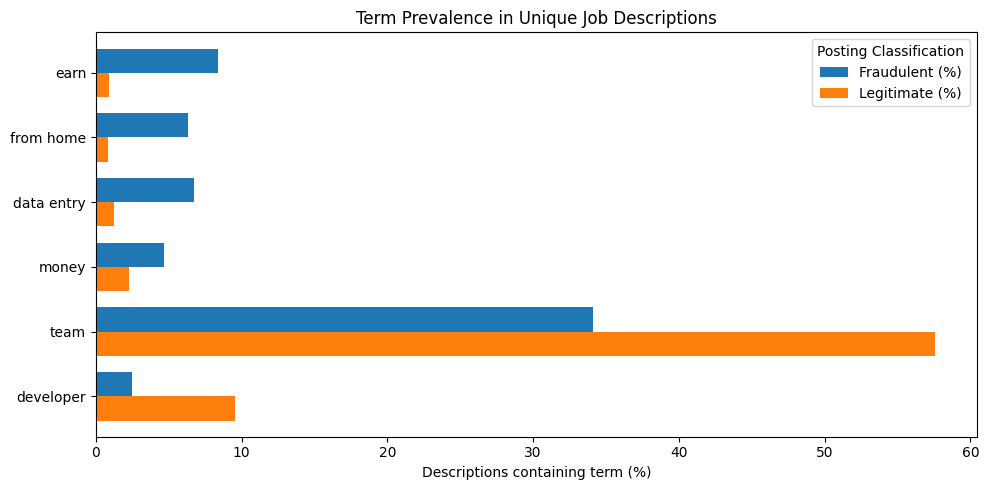

In [ ]:
#charts some of the most impactful terms for both fraudulent and authentic postings
description_terms = [
    'earn',
    'from home',
    'data entry',
    'money',
    'team',
    'developer'
]

plot_df = (
    unique_prevalence_df[
        unique_prevalence_df['Term'].isin(description_terms)
    ]
    .set_index('Term')
    .loc[description_terms]
)

ax = plot_df[
    ['Fraudulent (%)', 'Legitimate (%)']
].plot(
    kind='barh',
    figsize=(10, 5),
    width=0.75
)

ax.set_title(
    'Term Prevalence in Unique Job Descriptions'
)
ax.set_xlabel('Descriptions containing term (%)')
ax.set_ylabel('')
ax.invert_yaxis()

plt.legend(title='Posting Classification')
plt.tight_layout()
plt.show()

The analysis of unique job descriptions showed differences in the language used by fraudulent and legitimate postings. Terms associated with earnings and certain properties such as earn, from home, and data entry appeared more often in fraudulent postings. On the other hand, terms such as team and developer showed up more often in authentic posts. The differences were consistent even after removing exact duplicate descriptions suggesting they were not caused by repeated descriptions across postings.

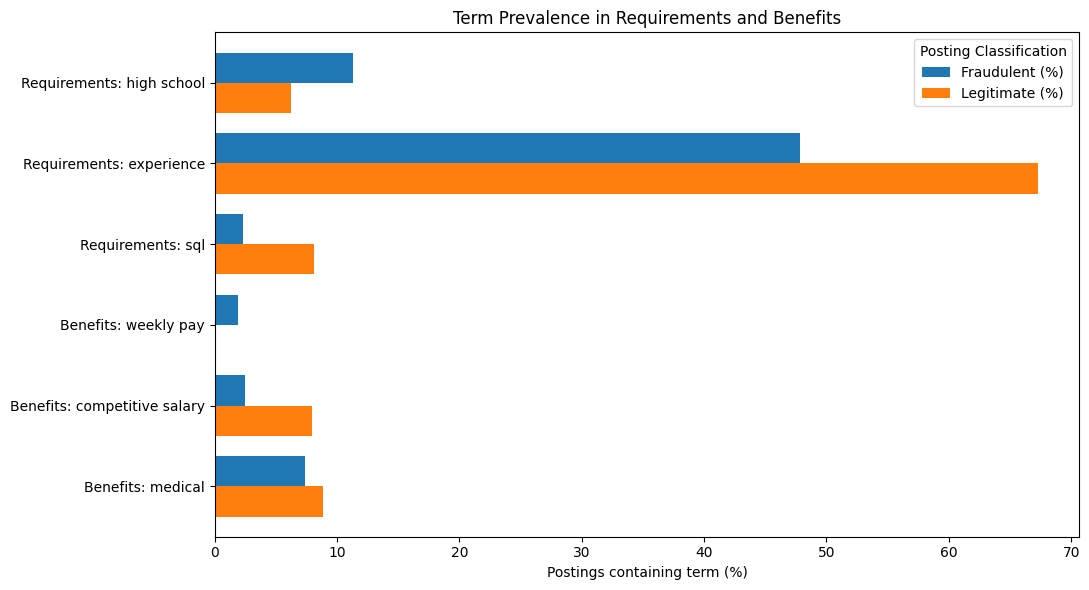

In [ ]:
#graphs some of the most impactful terms in requirements and benefits sections
requirements_plot = requirements_prevalence[
    requirements_prevalence['Term'].isin([
        'high school',
        'experience',
        'sql'
    ])
].copy()

requirements_plot['Term'] = (
    'Requirements: ' + requirements_plot['Term']
)

benefits_plot = benefits_prevalence[
    benefits_prevalence['Term'].isin([
        'weekly pay',
        'competitive salary',
        'medical'
    ])
].copy()

benefits_plot['Term'] = (
    'Benefits: ' + benefits_plot['Term']
)

combined_plot = pd.concat(
    [requirements_plot, benefits_plot],
    ignore_index=True
)

ax = combined_plot.set_index('Term')[
    ['Fraudulent (%)', 'Legitimate (%)']
].plot(
    kind='barh',
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    'Term Prevalence in Requirements and Benefits'
)
ax.set_xlabel('Postings containing term (%)')
ax.set_ylabel('')
ax.invert_yaxis()

plt.legend(title='Posting Classification')
plt.tight_layout()
plt.show()

The requirements and benefits fields also showed differences between fraudulent and legitimate postings. Fraudulent posts mentioned high school qualifications while authentic posts more often mentioned professional experience and technical skills. In the benefits field, weekly pay was more often seen in fraudulent posts while competitive salary was seen more often in authentic posts. However, some terms such as medical were seen in both classes almost equally.

##Conclusion

The language analysis found several differences between fraudulent and legitimate job postings in the EMSCAD dataset. Looking at the logistic regression coefficients it was found that fraudulent postings more frequently contained language associated with earnings, remote work, and certain job characteristics such as "earn", "from home", and "data entry". Authentic postings more often contained terms relating to the organization and profession such as "team", "experience", and "developer".

The expanded classification model also found differences in company profiles, job requirements, and benefits. Fraudulent postings more often referenced a basic education and compensation related phrases while authentic postings more often mentioned professional experience, technical skills, and standard employment benefits. However, not every coefficient related directly to differences in term prevalence showing that they must be interpreted in the context of other features.

It was found that some of the fraud associated terms were due to repeated or very similar fields across separate postings. The phrase "aker solutions" appeared across multiple job descriptions sharing very similar language that were all fraudulent. The term bonus appeared in 46 fraudulent postings but came from only 2 unique company profiles that were used for multiple postings. This limitation shows that the model may learn dataset specific patterns as well as general differences between fraudulent and authentic posts.

Company profile language showed significant differences between fraudulent and authentic postings. In the postings with an available company profile, the phrase "we are" appeared in 29.7% of authentic postings compared with 2.82% of fraudulent. However, it was found that some of the fraud associated terms were impacted by repeated company profiles. The term "bonus" appeared in 21.6% of fraudulent postings with company profiles but they all came from only 2 unique profiles that were repeatedly used. After removing duplicate profiles, the percentage dropped to 4.35%.

The analysis gave insight into the text features that can help identify fraudulent job postings while also showing the limitations. The expanded model achieved a fraud F1 score of 0.841 on the held back test set but the performance on new data containing brand new company profiles and templates could be much lower.